## VE11 vs noVE11 per-ROI beta scatterplots

Compare basis-function coefficients (`beta_hat`) between matched **VE11** and **noVE11** arms.

**Toggle pheno in the next cell** (`bmip` or `perc_median`); paths, BF indices, titles, and output dirs follow from that.


In [85]:
%% CONFIG — change only PHENO here, then Run All
% 'bmip' or 'perc_median'
PHENO = 'perc_median';

CEPH = '/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis';
ANALYSIS_ROOT = 've11_vs_noVE11_6_0';

switch PHENO
    case 'bmip'
        results_run = 'results_2026_09_02';
        design_tag = 'Sbmi';
        ve11_desmat = 'designmat1_SbmiSageSpdsSexIncEducPCsScanner_nodemean';
        nove11_desmat = 'designmat1_SbmiSageSpdsSexIncEducPCsScanSoft_nodemean';
        pheno_bf_grep = '^bf_bmi';
        pheno_label = 'BMI percentile';
        pheno_file_tag = 'sBMI';
    case 'perc_median'
        results_run = 'results_2026_10_02';
        design_tag = 'Sperc';
        ve11_desmat = 'designmat1_SpercSageSpdsSexIncEducPCsScanner_nodemean';
        nove11_desmat = 'designmat1_SpercSageSpdsSexIncEducPCsScanSoft_nodemean';
        pheno_bf_grep = '^bf_perc_median';
        pheno_label = 'Percent from median';
        pheno_file_tag = 'sPercMedian';
    otherwise
        error('PHENO must be ''bmip'' or ''perc_median'' (got %s).', PHENO);
end

est_name = 'FEMA_wrapper_output_voxel_rni_estimates.mat';
ve11_est = fullfile(CEPH, ANALYSIS_ROOT, PHENO, 'VE11', 'results', results_run, ve11_desmat, est_name);
nove11_est = fullfile(CEPH, ANALYSIS_ROOT, PHENO, 'noVE11', 'results', results_run, nove11_desmat, est_name);
outdir = fullfile(CEPH, ANALYSIS_ROOT, 'matching', sprintf('%s_plots', PHENO));

fprintf('PHENO=%s | results_run=%s\n', PHENO, results_run);
fprintf('VE11:   %s\n', ve11_est);
fprintf('noVE11: %s\n', nove11_est);
fprintf('outdir: %s\n', outdir);


PHENO=perc_median | results_run=results_2026_10_02
VE11:   /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/perc_median/VE11/results/results_2026_10_02/designmat1_SpercSageSpdsSexIncEducPCsScanner_nodemean/FEMA_wrapper_output_voxel_rni_estimates.mat
noVE11: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/perc_median/noVE11/results/results_2026_10_02/designmat1_SpercSageSpdsSexIncEducPCsScanSoft_nodemean/FEMA_wrapper_output_voxel_rni_estimates.mat
outdir: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/perc_median_plots


In [86]:
%% Load FEMA estimates + atlas (uses paths from config cell)
noVE11 = load(nove11_est, 'beta_hat', 'beta_se', 'colnames_model');
VE11 = load(ve11_est, 'beta_hat', 'beta_se', 'colnames_model');
load('/usr/pubsw/packages/cmig/cmig_tools/support_files/roi2ABCDAtlasMaps.mat');

% Resolve BF row indices from colnames (do not hardcode 1:4 / 5:9)
pheno_bf_idx = find(~cellfun(@isempty, regexp(noVE11.colnames_model, pheno_bf_grep, 'once')));
age_bf_idx = find(~cellfun(@isempty, regexp(noVE11.colnames_model, '^bf_age', 'once')));
if isempty(pheno_bf_idx)
    error('No pheno BF columns matching %s in colnames_model.', pheno_bf_grep);
end
if isempty(age_bf_idx)
    error('No bf_age columns in colnames_model.');
end

fprintf('Pheno BF cols (%s): %s\n', pheno_label, strjoin(noVE11.colnames_model(pheno_bf_idx), ', '));
fprintf('Age BF cols: %s\n', strjoin(noVE11.colnames_model(age_bf_idx), ', '));

if ~exist(outdir, 'dir'), mkdir(outdir); end


Pheno BF cols (Percent from median): bf_perc_median_1, bf_perc_median_2, bf_perc_median_3, bf_perc_median_4
Age BF cols: bf_age_1, bf_age_2, bf_age_3, bf_age_4, bf_age_5


### Quick check (all pheno BF coeffs, all voxels)


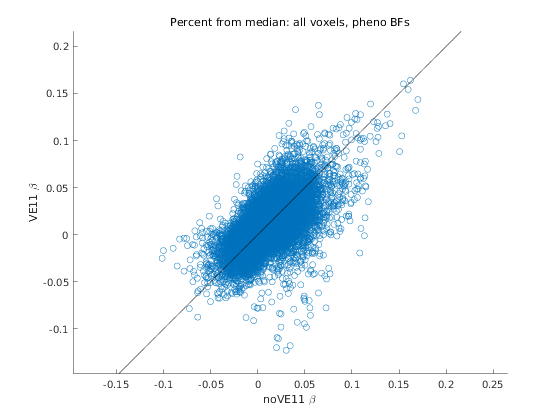

In [87]:
scatter(rowvec(noVE11.beta_hat(pheno_bf_idx, :)), rowvec(VE11.beta_hat(pheno_bf_idx, :)));
axis equal
hold on
x = linspace(min(xlim), max(xlim), 100);
plot(x, x, 'k-');
xlabel('noVE11 \beta');
ylabel('VE11 \beta');
title(sprintf('%s: all voxels, pheno BFs', pheno_label), 'FontWeight', 'normal');
hold off


### Pheno BFs — aseg ROIs

One figure per ROI; colors = pheno spline basis coefficients.


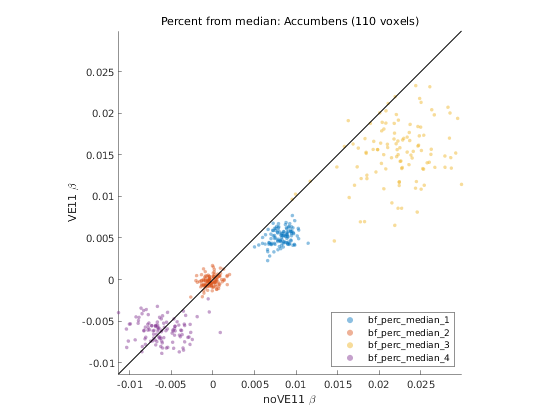

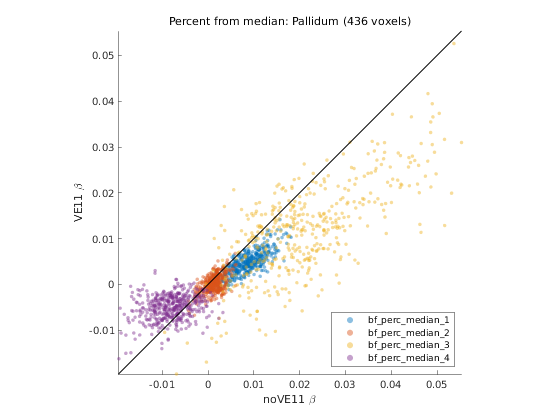

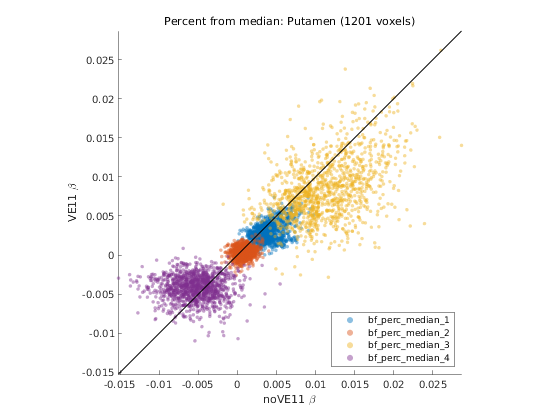

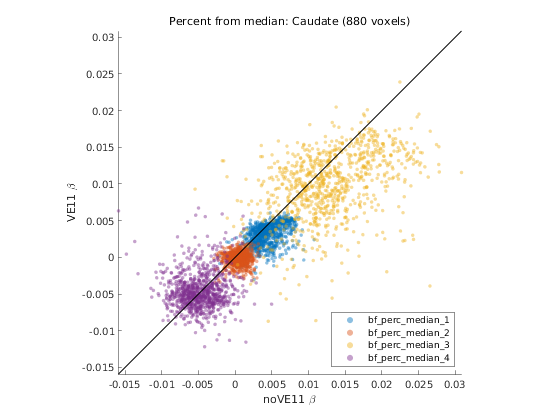

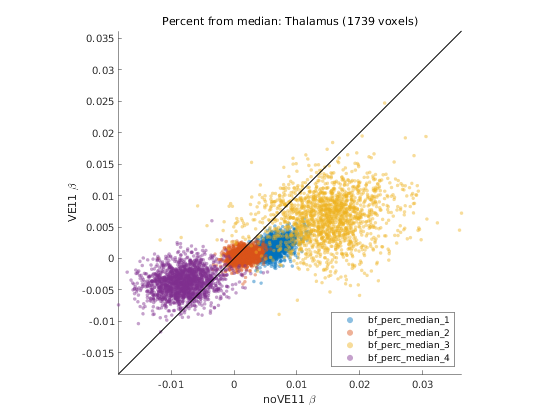

In [88]:
roi_names = {'Accumbens', 'Pallidum', 'Putamen', 'Caudate', 'Thalamus'};
bf_idx = pheno_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

for i = 1:numel(roi_names)
    idx_roi = find(contains(roi2atlas.aseg.roinames, roi_names{i}));
    if isempty(idx_roi)
        warning('No aseg match for %s', roi_names{i});
        continue
    end
    roi_all = sum(roi2atlas.aseg.roimat(idx_roi, :), 1);
    roi_vox = find(roi_all);

    figure('Name', roi_names{i});
    hold on
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(x, y, 12, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end
    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis equal
    xlim(lims); ylim(lims);
    xlabel('noVE11 \beta');
    ylabel('VE11 \beta');
    title(sprintf('%s: %s (%d voxels)', pheno_label, roi_names{i}, numel(roi_vox)), 'FontWeight', 'normal');
    legend('Location', 'southeast', 'Interpreter', 'none');
    fname = fullfile(outdir, sprintf('ve11_vs_nove11_%s_%s.png', pheno_file_tag, roi_names{i}));
    exportgraphics(gcf, fname, 'Resolution', 300);
    exportgraphics(gcf, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
    hold off
    drawnow
end


### Pheno BFs — fiber ROIs


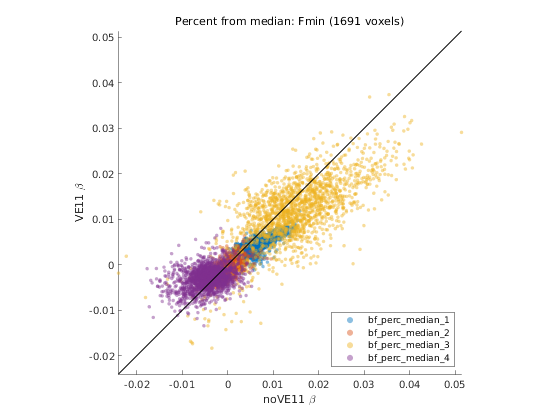

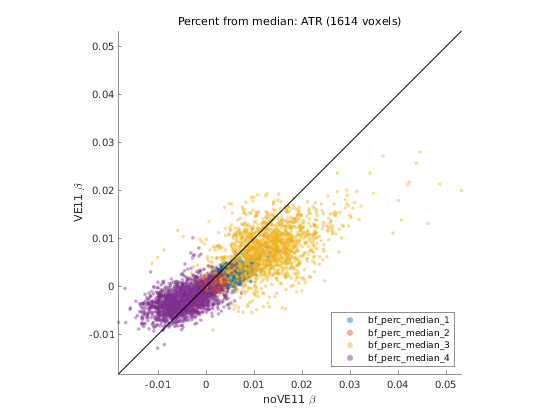

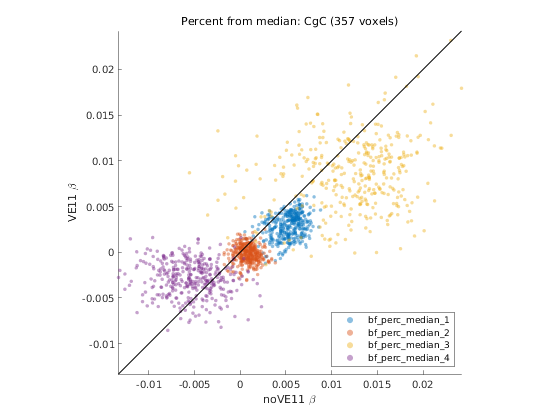

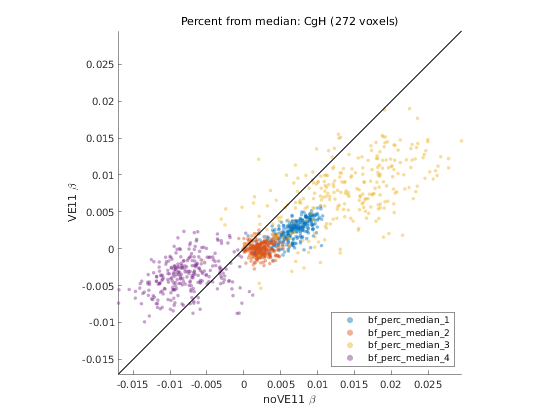

In [89]:
roi_names = {'Fmin', 'ATR', 'CgC', 'CgH'};
bf_idx = pheno_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

for i = 1:numel(roi_names)
    idx_roi = find(contains(roi2atlas.fiber.roinames, roi_names{i}));
    if isempty(idx_roi)
        warning('No fiber match for %s', roi_names{i});
        continue
    end
    roi_all = sum(roi2atlas.fiber.roimat(idx_roi, :), 1);
    roi_vox = find(roi_all);

    figure('Name', roi_names{i});
    hold on
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(x, y, 12, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end
    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis equal
    xlim(lims); ylim(lims);
    xlabel('noVE11 \beta');
    ylabel('VE11 \beta');
    title(sprintf('%s: %s (%d voxels)', pheno_label, roi_names{i}, numel(roi_vox)), 'FontWeight', 'normal');
    legend('Location', 'southeast', 'Interpreter', 'none');
    fname = fullfile(outdir, sprintf('ve11_vs_nove11_%s_%s.png', pheno_file_tag, roi_names{i}));
    exportgraphics(gcf, fname, 'Resolution', 300);
    exportgraphics(gcf, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
    hold off
    drawnow
end


### Age BFs — aseg ROIs


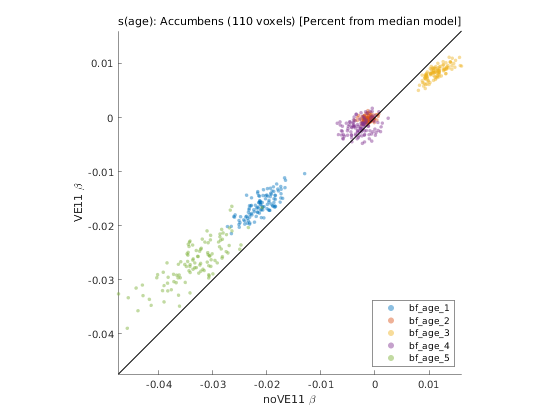

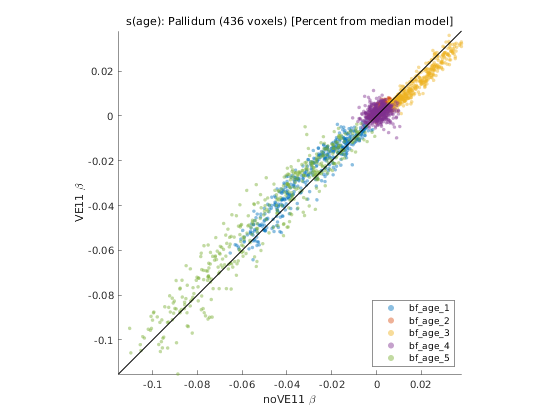

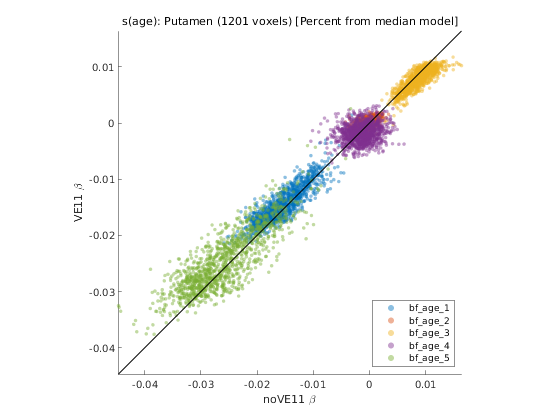

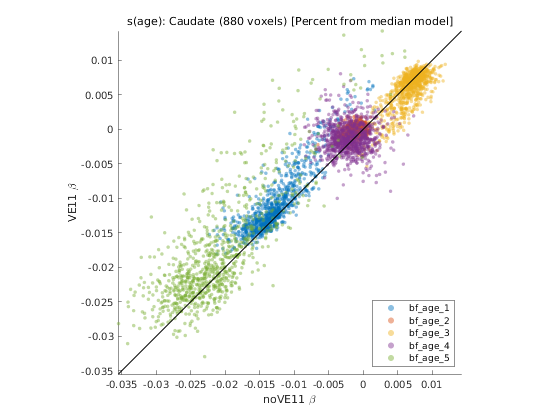

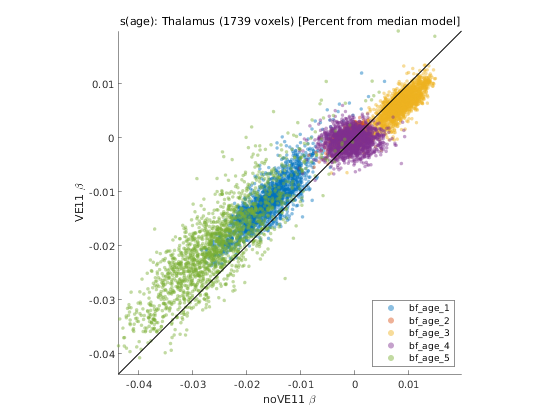

In [90]:
roi_names = {'Accumbens', 'Pallidum', 'Putamen', 'Caudate', 'Thalamus'};
bf_idx = age_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

for i = 1:numel(roi_names)
    idx_roi = find(contains(roi2atlas.aseg.roinames, roi_names{i}));
    if isempty(idx_roi)
        warning('No aseg match for %s', roi_names{i});
        continue
    end
    roi_all = sum(roi2atlas.aseg.roimat(idx_roi, :), 1);
    roi_vox = find(roi_all);

    figure('Name', roi_names{i});
    hold on
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(x, y, 12, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end
    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis equal
    xlim(lims); ylim(lims);
    xlabel('noVE11 \beta');
    ylabel('VE11 \beta');
    title(sprintf('s(age): %s (%d voxels) [%s model]', roi_names{i}, numel(roi_vox), pheno_label), 'FontWeight', 'normal');
    legend('Location', 'southeast', 'Interpreter', 'none');
    fname = fullfile(outdir, sprintf('ve11_vs_nove11_sAge_%s.png', roi_names{i}));
    exportgraphics(gcf, fname, 'Resolution', 300);
    exportgraphics(gcf, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
    hold off
    drawnow
end


### Age BFs — fiber ROIs


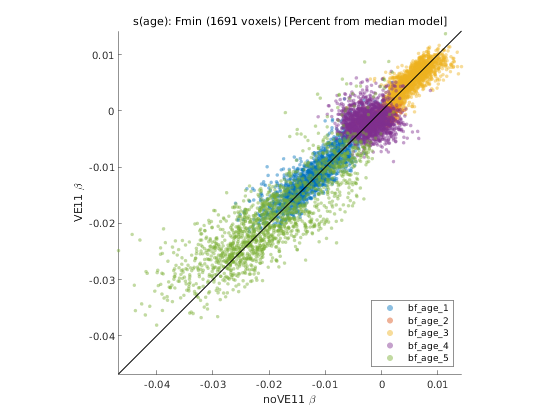

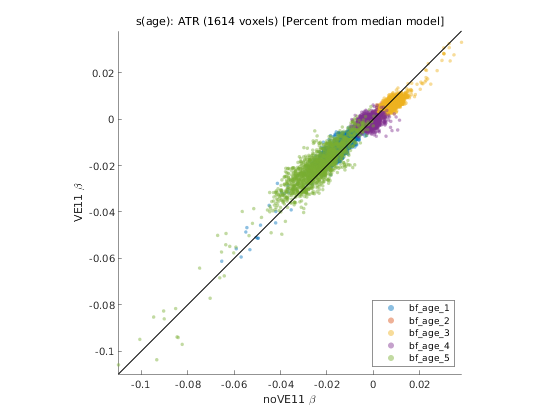

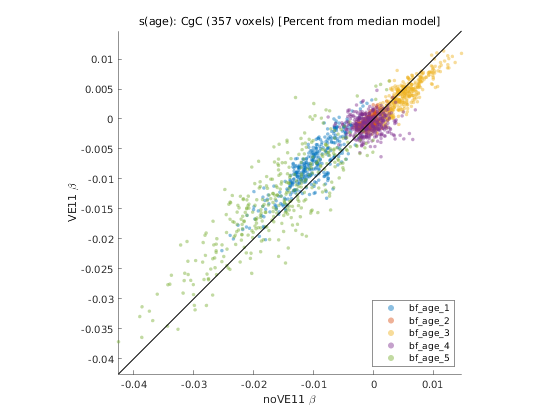

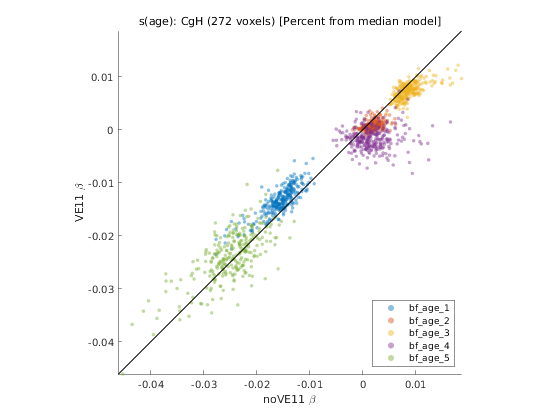

In [91]:
roi_names = {'Fmin', 'ATR', 'CgC', 'CgH'};
bf_idx = age_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

for i = 1:numel(roi_names)
    idx_roi = find(contains(roi2atlas.fiber.roinames, roi_names{i}));
    if isempty(idx_roi)
        warning('No fiber match for %s', roi_names{i});
        continue
    end
    roi_all = sum(roi2atlas.fiber.roimat(idx_roi, :), 1);
    roi_vox = find(roi_all);

    figure('Name', roi_names{i});
    hold on
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(x, y, 12, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end
    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis equal
    xlim(lims); ylim(lims);
    xlabel('noVE11 \beta');
    ylabel('VE11 \beta');
    title(sprintf('s(age): %s (%d voxels) [%s model]', roi_names{i}, numel(roi_vox), pheno_label), 'FontWeight', 'normal');
    legend('Location', 'southeast', 'Interpreter', 'none');
    fname = fullfile(outdir, sprintf('ve11_vs_nove11_sAge_%s.png', roi_names{i}));
    exportgraphics(gcf, fname, 'Resolution', 300);
    exportgraphics(gcf, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
    hold off
    drawnow
end


### Combined 9-panel figures

Same ROI set / layout as s10e (`2` columns, last panel centered). Each panel is styled like the single-ROI plots above.


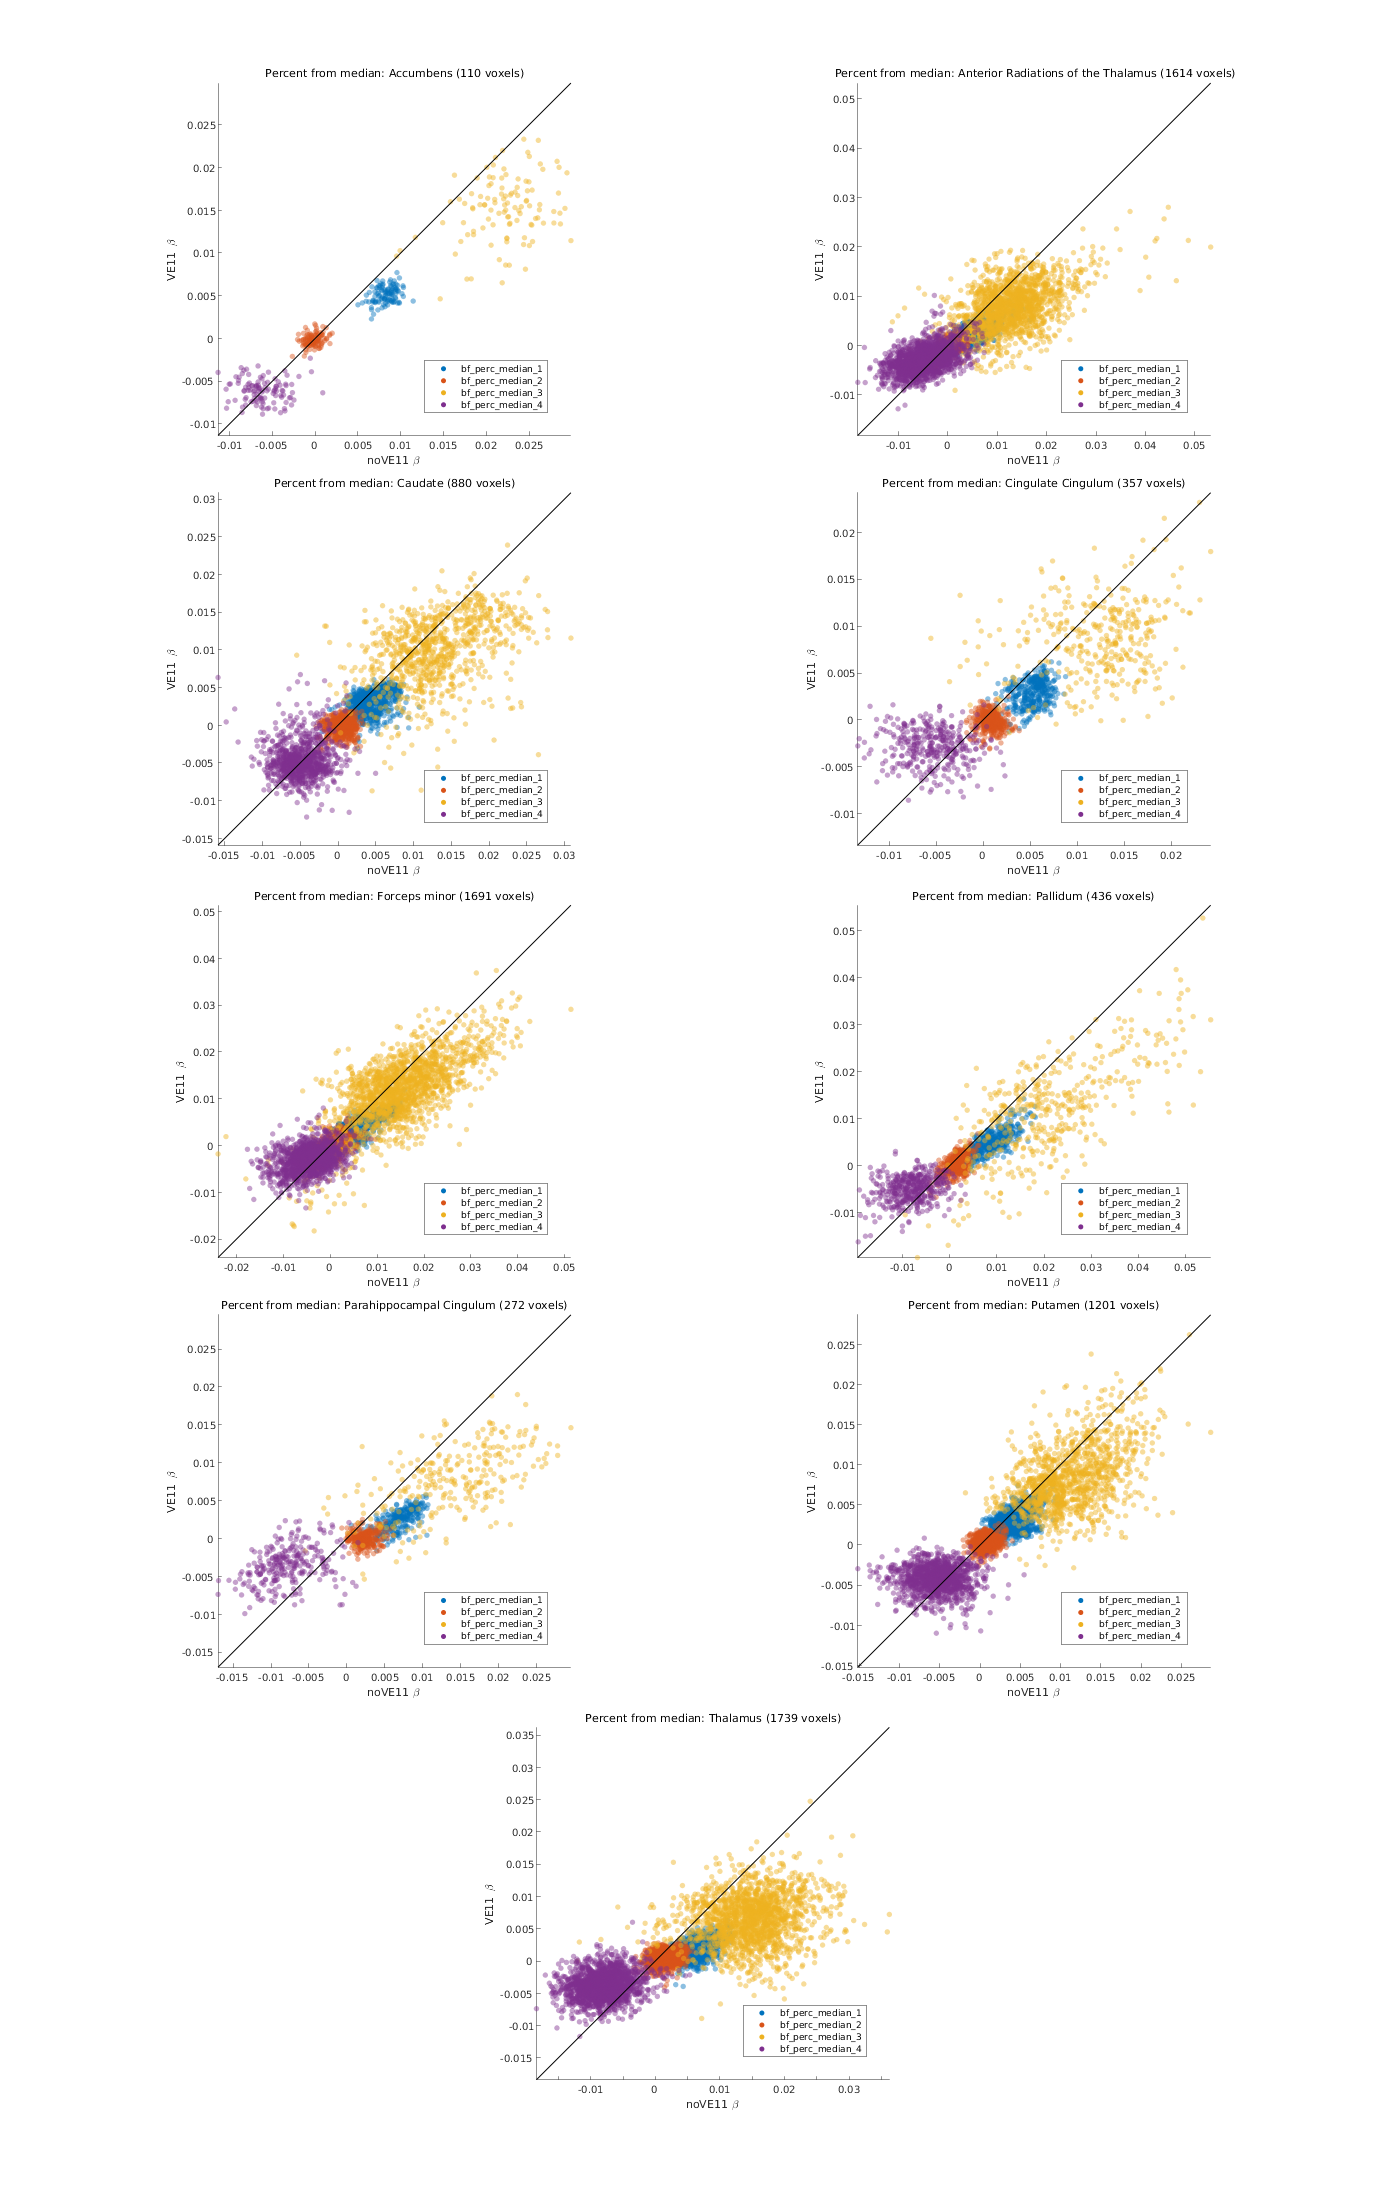

Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/perc_median_plots/ve11_vs_nove11_sPercMedian_selected_ROIs_combined.png (+ pdf)


In [92]:
%% Combined 9-panel: pheno BFs (fresh)
% Layout matches s10e; panel styling matches the single-ROI cells above.

selected_rois = {
    'Accumbens', 'aseg',  'Accumbens';
    'ATR',       'fiber', 'Anterior Radiations of the Thalamus';
    'Caudate',   'aseg',  'Caudate';
    'CgC',       'fiber', 'Cingulate Cingulum';
    'Fmin',      'fiber', 'Forceps minor';
    'Pallidum',  'aseg',  'Pallidum';
    'CgH',       'fiber', 'Parahippocampal Cingulum';
    'Putamen',   'aseg',  'Putamen';
    'Thalamus',  'aseg',  'Thalamus';
    };
[~, ord] = sort(selected_rois(:, 3));
selected_rois = selected_rois(ord, :);

bf_idx = pheno_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

n_rois = size(selected_rois, 1);
n_rows = ceil(n_rois / 2);

fig = figure('Name', sprintf('Combined %s BFs', pheno_label), ...
    'Color', 'w', 'Position', [80 40 1400 2200]);
tiledlayout(n_rows, 4, 'TileSpacing', 'compact', 'Padding', 'compact');

for idx = 1:n_rois
    match_key = selected_rois{idx, 1};
    atlas_src = selected_rois{idx, 2};
    disp_name = selected_rois{idx, 3};

    % 2-column layout; last panel centered (spans middle two of 4 cols)
    if idx < n_rois
        row = floor((idx - 1) / 2) + 1;
        side = mod(idx - 1, 2);           % 0 = left, 1 = right
        col_start = 1 + side * 2;
        ax = nexttile((row - 1) * 4 + col_start, [1 2]);
    else
        ax = nexttile((n_rows - 1) * 4 + 2, [1 2]);
    end

    if strcmp(atlas_src, 'aseg')
        idx_roi = find(contains(roi2atlas.aseg.roinames, match_key));
        if isempty(idx_roi)
            warning('No aseg match for %s', match_key);
            title(ax, disp_name, 'FontWeight', 'normal');
            continue
        end
        roi_all = sum(roi2atlas.aseg.roimat(idx_roi, :), 1);
    else
        idx_roi = find(contains(roi2atlas.fiber.roinames, match_key));
        if isempty(idx_roi)
            warning('No fiber match for %s', match_key);
            title(ax, disp_name, 'FontWeight', 'normal');
            continue
        end
        roi_all = sum(roi2atlas.fiber.roimat(idx_roi, :), 1);
    end
    roi_vox = find(roi_all);

    hold(ax, 'on');
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(ax, x, y, 10, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end

    % Legend proxies — MarkerSize here controls the legend dots
    h_leg = gobjects(numel(bf_idx), 1);
    for k = 1:numel(bf_idx)
        h_leg(k) = plot(ax, NaN, NaN, 'o', ...
            'MarkerSize', 5, ...
            'MarkerFaceColor', bf_colors(k, :), ...
            'MarkerEdgeColor', 'none', ...
            'DisplayName', bf_labels{k});
    end
    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(ax, lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis(ax, 'equal');
    xlim(ax, lims); ylim(ax, lims);
    xlabel(ax, 'noVE11 \beta');
    ylabel(ax, 'VE11 \beta');
    title(ax, sprintf('%s: %s (%d voxels)', pheno_label, disp_name, numel(roi_vox)), ...
        'FontWeight', 'normal');
    %legend(ax, 'Location', 'southeast', 'Interpreter', 'none');
    legend(ax, h_leg, 'Location', 'southeast', 'Interpreter', 'none');
    hold(ax, 'off');
end

fname = fullfile(outdir, sprintf('ve11_vs_nove11_%s_selected_ROIs_combined.png', pheno_file_tag));
exportgraphics(fig, fname, 'Resolution', 300);
exportgraphics(fig, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
fprintf('Saved %s (+ pdf)\n', fname);


### Combined age-BF 9-panel figure


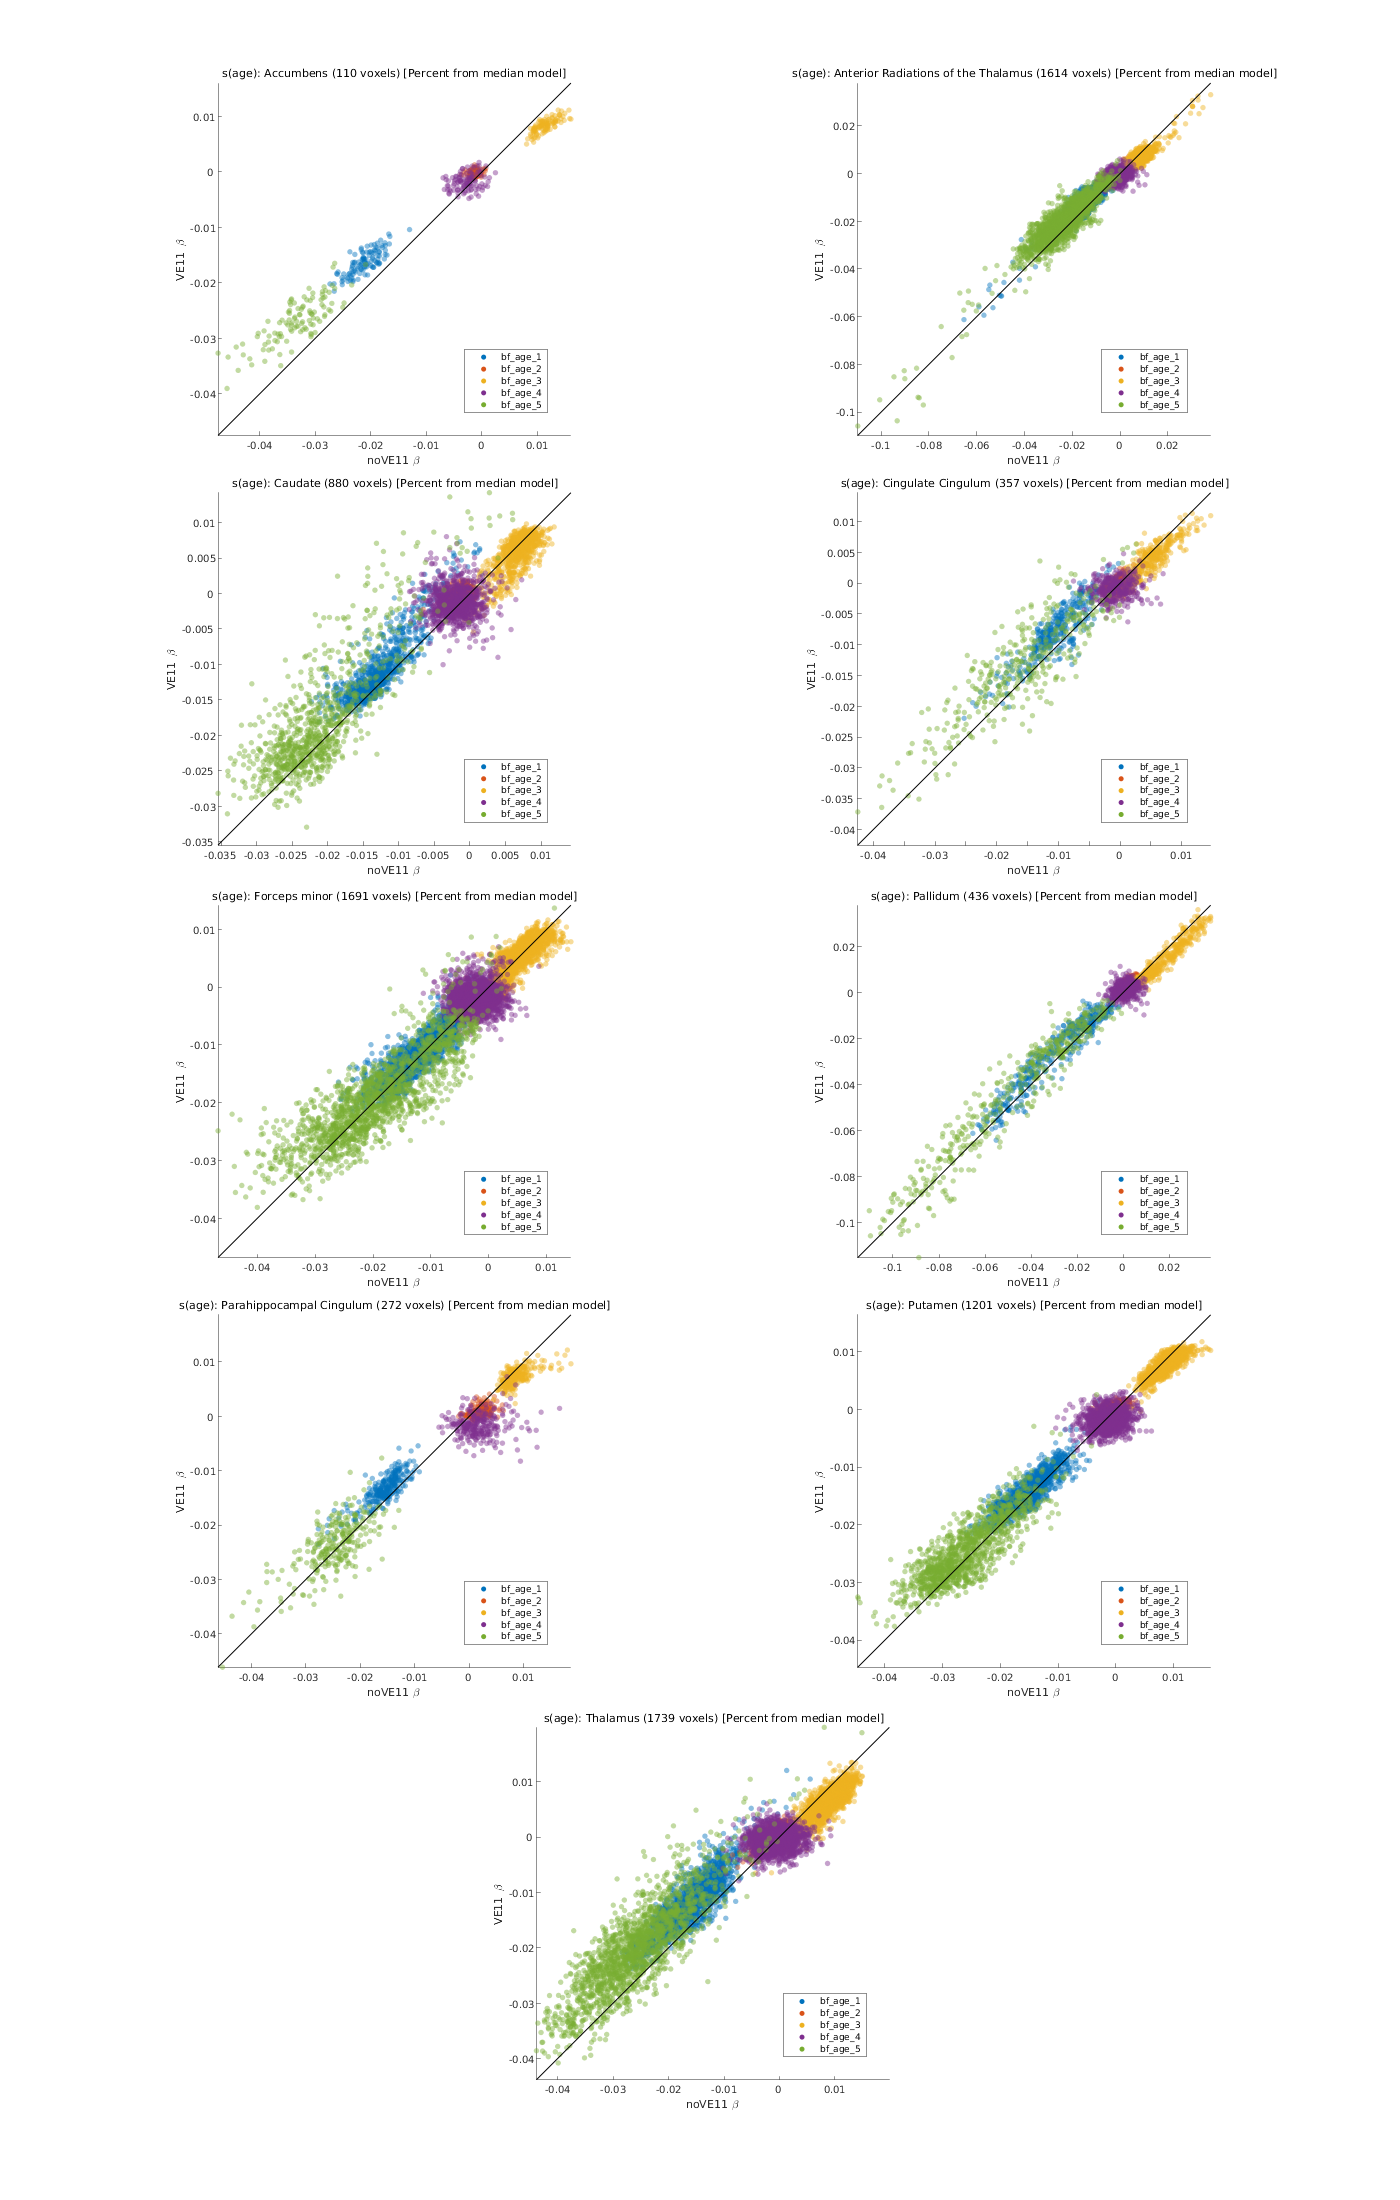

Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/ve11_vs_noVE11_6_0/matching/perc_median_plots/ve11_vs_nove11_sAge_selected_ROIs_combined.png (+ pdf)


In [93]:
%% Combined 9-panel: age BFs (fresh)
% Same layout / styling as the pheno combined cell above.

selected_rois = {
    'Accumbens', 'aseg',  'Accumbens';
    'ATR',       'fiber', 'Anterior Radiations of the Thalamus';
    'Caudate',   'aseg',  'Caudate';
    'CgC',       'fiber', 'Cingulate Cingulum';
    'Fmin',      'fiber', 'Forceps minor';
    'Pallidum',  'aseg',  'Pallidum';
    'CgH',       'fiber', 'Parahippocampal Cingulum';
    'Putamen',   'aseg',  'Putamen';
    'Thalamus',  'aseg',  'Thalamus';
    };
[~, ord] = sort(selected_rois(:, 3));
selected_rois = selected_rois(ord, :);

bf_idx = age_bf_idx;
bf_colors = lines(numel(bf_idx));
bf_labels = noVE11.colnames_model(bf_idx);

n_rois = size(selected_rois, 1);
n_rows = ceil(n_rois / 2);

fig = figure('Name', 'Combined age BFs', ...
    'Color', 'w', 'Position', [80 40 1400 2200]);
tiledlayout(n_rows, 4, 'TileSpacing', 'compact', 'Padding', 'compact');

for idx = 1:n_rois
    match_key = selected_rois{idx, 1};
    atlas_src = selected_rois{idx, 2};
    disp_name = selected_rois{idx, 3};

    if idx < n_rois
        row = floor((idx - 1) / 2) + 1;
        side = mod(idx - 1, 2);
        col_start = 1 + side * 2;
        ax = nexttile((row - 1) * 4 + col_start, [1 2]);
    else
        ax = nexttile((n_rows - 1) * 4 + 2, [1 2]);
    end

    if strcmp(atlas_src, 'aseg')
        idx_roi = find(contains(roi2atlas.aseg.roinames, match_key));
        if isempty(idx_roi)
            warning('No aseg match for %s', match_key);
            title(ax, disp_name, 'FontWeight', 'normal');
            continue
        end
        roi_all = sum(roi2atlas.aseg.roimat(idx_roi, :), 1);
    else
        idx_roi = find(contains(roi2atlas.fiber.roinames, match_key));
        if isempty(idx_roi)
            warning('No fiber match for %s', match_key);
            title(ax, disp_name, 'FontWeight', 'normal');
            continue
        end
        roi_all = sum(roi2atlas.fiber.roimat(idx_roi, :), 1);
    end
    roi_vox = find(roi_all);

    hold(ax, 'on');
    all_vals = [];
    for k = 1:numel(bf_idx)
        x = noVE11.beta_hat(bf_idx(k), roi_vox);
        y = VE11.beta_hat(bf_idx(k), roi_vox);
        scatter(ax, x, y, 10, bf_colors(k, :), 'filled', ...
            'MarkerFaceAlpha', 0.45, 'DisplayName', bf_labels{k});
        all_vals = [all_vals, x(:)', y(:)']; %#ok<AGROW>
    end

    % Legend proxies — MarkerSize here controls the legend dots
    h_leg = gobjects(numel(bf_idx), 1);
    for k = 1:numel(bf_idx)
        h_leg(k) = plot(ax, NaN, NaN, 'o', ...
            'MarkerSize', 5, ...
            'MarkerFaceColor', bf_colors(k, :), ...
            'MarkerEdgeColor', 'none', ...
            'DisplayName', bf_labels{k});
    end

    lims = [min(all_vals, [], 'omitnan'), max(all_vals, [], 'omitnan')];
    plot(ax, lims, lims, 'k-', 'LineWidth', 1, 'HandleVisibility', 'off');
    axis(ax, 'equal');
    xlim(ax, lims); ylim(ax, lims);
    xlabel(ax, 'noVE11 \beta');
    ylabel(ax, 'VE11 \beta');
    title(ax, sprintf('s(age): %s (%d voxels) [%s model]', ...
        disp_name, numel(roi_vox), pheno_label), 'FontWeight', 'normal');
    %legend(ax, 'Location', 'southeast', 'Interpreter', 'none');
    legend(ax, h_leg, 'Location', 'southeast', 'Interpreter', 'none');
    hold(ax, 'off');
end

fname = fullfile(outdir, 've11_vs_nove11_sAge_selected_ROIs_combined.png');
exportgraphics(fig, fname, 'Resolution', 300);
exportgraphics(fig, strrep(fname, '.png', '.pdf'), 'ContentType', 'vector');
fprintf('Saved %s (+ pdf)\n', fname);
